<a href="https://colab.research.google.com/github/Dedeepya0510/CSA4703---Deep-Learning/blob/main/Lab%20Experiment/Exp_6.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

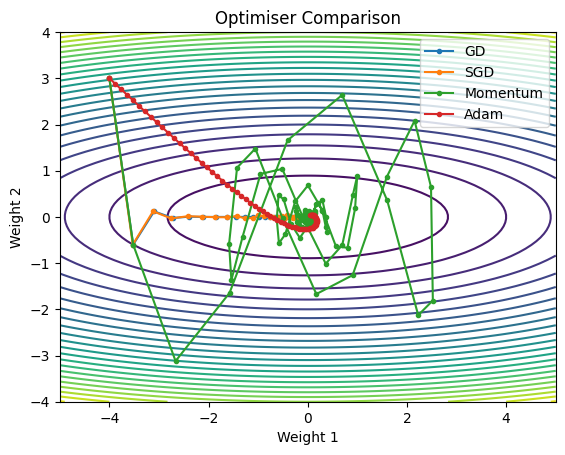

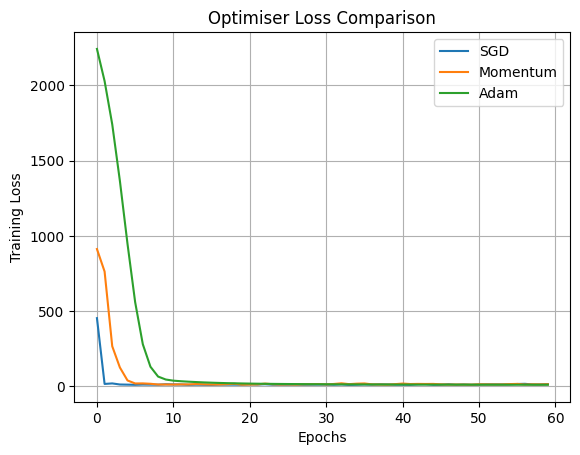

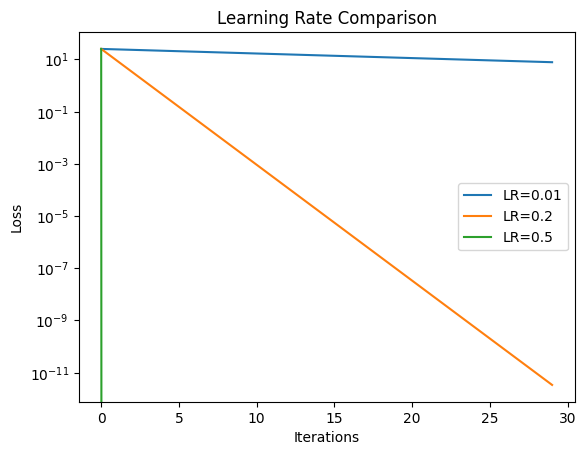

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

# 1. Define Loss Function
def gradient(w):
    return np.array([w[0],10*w[1]])

# Optimisation Algorithms
def optimizer(name,lr=0.12,steps=80):

    w = np.array([-4.0,3.0])
    velocity = np.zeros(2)
    m = np.zeros(2)
    v = np.zeros(2)

    path = [w.copy()]

    for t in range(1,steps+1):

        g = gradient(w)

        if name == "GD":
            update = g

        elif name == "SGD":
            update = g + np.random.normal(0,0.15,2)

        elif name == "Momentum":
            velocity = 0.9*velocity + g
            update = velocity

        elif name == "Adam":
            m = 0.9*m + 0.1*g
            v = 0.999*v + 0.001*(g*g)

            m_hat = m/(1-0.9**t)
            v_hat = v/(1-0.999**t)

            update = m_hat/(np.sqrt(v_hat)+1e-8)

        w = w-lr*update
        path.append(w.copy())

    return np.array(path)

# 2. Contour Plot
x = np.linspace(-5,5,100)
y = np.linspace(-4,4,100)

X,Y = np.meshgrid(x,y)
Z = 0.5*(X**2+10*Y**2)

plt.contour(X,Y,Z,levels=25)

for name in ["GD","SGD","Momentum","Adam"]:

    p = optimizer(name)

    plt.plot(p[:,0],p[:,1],marker='.',label=name)

plt.title("Optimiser Comparison")
plt.xlabel("Weight 1")
plt.ylabel("Weight 2")
plt.legend()
plt.show()

# 3. Generate Delivery Dataset
np.random.seed(42)

N = 1000

X = np.column_stack([
    np.random.uniform(1,30,N),
    np.random.uniform(0,1,N),
    np.random.uniform(0.2,20,N),
    np.random.uniform(0,24,N)
])

y = (
    8 + 1.7*X[:,0] + 12*X[:,1]
    + 0.35*X[:,2]
    + 0.25*np.abs(X[:,3]-13)
    + np.random.normal(0,3,N)
)

X_train,X_test,y_train,y_test = train_test_split(
    X,y,test_size=0.2,random_state=42
)

scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

# 4. Keras Optimiser Comparison
histories = {}

for name,opt in [
    ("SGD",tf.keras.optimizers.SGD(learning_rate=0.01)),
    ("Momentum",tf.keras.optimizers.SGD(learning_rate=0.01,momentum=0.9)),
    ("Adam",tf.keras.optimizers.Adam(learning_rate=0.01))
]:

    model = tf.keras.Sequential([
        tf.keras.layers.Input(shape=(4,)),
        tf.keras.layers.Dense(16,activation='relu'),
        tf.keras.layers.Dense(1)
    ])

    model.compile(optimizer=opt,loss='mse')

    history = model.fit(
        X_train,y_train,
        epochs=60,
        batch_size=32,
        validation_split=0.2,
        verbose=0
    )

    histories[name] = history.history

# 5. Plot Loss
for name,h in histories.items():
    plt.plot(h['loss'],label=name)

plt.xlabel("Epochs")
plt.ylabel("Training Loss")
plt.title("Optimiser Loss Comparison")
plt.legend()
plt.grid()
plt.show()

# Learning Rate Comparison
for lr in [0.01,0.2,0.5]:

    w = 5
    losses = []

    for i in range(30):
        losses.append(w**2)
        w = w-lr*2*w

    plt.plot(losses,label=f"LR={lr}")

plt.yscale("log")
plt.xlabel("Iterations")
plt.ylabel("Loss")
plt.title("Learning Rate Comparison")
plt.legend()
plt.show()